# 1 Introducción

El siguiente ejemplo modifica el color de una imágen parametrizada, invertiendole el mismo. El cálculo de la se realiza aplicando la siguiente formula a cada color RGB del pixel:

<center>$ pixelinvertido = 255 - pixeloriginal$</center>

EL objetivo es enseñar el funcionamiento del Lenguaje Python, CUDA y el manejo de imagenes a bajo nivel. El ejemplo es ilustrativo, ya que internamente el módulo Pillow posee varios filtros integrados.

-----
#Enunciado del Ejercicio

a)  Teniendo en cuenta el código secuencial del Filtro de inversion de colores de una imagen, que se ejecuta en la CPU, genere el kernel para ejecutar el mismo algoritmo en forma paralela en la gpu

---
## 2 Armado del ambiente
Toma la direcciòn web de una imagen con  acceso público en internet, la deja disponible al contexto de ejecuciòn del cuaderno colab.

In [1]:
#@title # 2.1 Parámetros de ejecución
#@markdown ---
#@markdown ### Especifique la URL de la imagen:
url_imagen = "https://raw.githubusercontent.com/soa-pc-unlam/ProgramacionConcurrente/main/Enunciados%20TPs/TP-GPU/Imagenes/MK-Maxi-Esteban.jpeg" #@param {type:"string"}

#@markdown ---
# Leo la imagen desde internet.
#!wget https://github.com/wvaliente/SOA_HPC/blob/main/unlam.jpg?raw=true -O imagen.jpg

# TODO: Mejorar informaciòn y resutlado de ejecución.
!wget {url_imagen} -O imagen.jpg



[0] Downloading 'https://raw.githubusercontent.com/soa-pc-unlam/ProgramacionConcurrente/main/Enunciados%20TPs/TP-GPU/Imagenes/MK-Maxi-Esteban.jpeg' ...
Saving 'imagen.jpg'
HTTP response 200  [https://raw.githubusercontent.com/soa-pc-unlam/ProgramacionConcurrente/main/Enunciados%20TPs/TP-GPU/Imagenes/MK-Maxi-Esteban.jpeg]


---
## 2.2 Instala en el cuaderno el módulo CUDA de Python.

In [2]:
!pip install pycuda

  Using cached pycuda-2026.1.tar.gz (1.7 MB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Using cached pytools-2026.1.1-py3-none-any.whl.metadata (2.9 kB)
  Using cached mako-1.4.3-py3-none-any.whl.metadata (2.9 kB)
  Using cached siphash24-1.9-cp314-cp314-win_amd64.whl.metadata (3.3 kB)
Using cached pytools-2026.1.1-py3-none-any.whl (99 kB)
Using cached siphash24-1.9-cp314-cp314-win_amd64.whl (79 kB)
Using cached mako-1.4.3-py3-none-any.whl (80 kB)
Failed to build pycuda


  error: subprocess-exited-with-error
  
  × Building wheel for pycuda (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> [239 lines of output]
      ***************************************************************
      *** WARNING: nvcc not in path.
      *** May need to set CUDA_INC_DIR for installation to succeed.
      ***************************************************************
      *************************************************************
      *** I have detected that you have not run configure.py.
      *************************************************************
      *** Additionally, no global config files were found.
      *** I will go ahead with the default configuration.
      *** In all likelihood, this will not work out.
      ***
      *** See README_SETUP.txt for more information.
      ***
      *** If the build does fail, just re-run configure.py with the
      *** correct arguments, and then retry. Good luck!
      *************************

---
# 3 Desarrollo
# Ejecución en CPU
Ejecución del algoritmo del filtro de brllo ejecutandose en form secuencial en  la CPU

C:\Users\leandro\AppData\Local\Temp\ipykernel_18776\372695334.py:15: DeprecationWarning: Image.Image.getdata is deprecated and will be removed in Pillow 14 (2027-10-15). Use get_flattened_data instead.
  datos = list(im.getdata())


imagen original


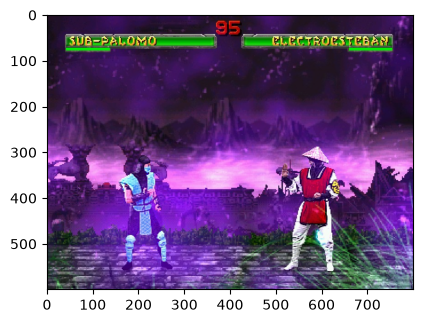

imagen con filtro


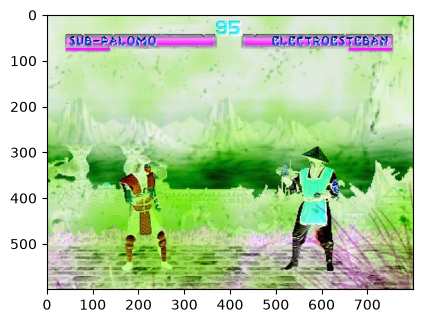

In [3]:
from pickle import FALSE
from PIL import Image
import matplotlib.pyplot as plt

import cProfile

#Poner SHOW_STATS en true para ver el tiempo de ejecucion y false para ocultarlo
SHOW_STATS=False

CM= 1/2.54
SIZE= 12*CM

#funcion que aplica el filtro de inversion de colores
def invert_color(im,out):
  datos = list(im.getdata())

  datos_invertidos = []
  for x in range(len(datos)):
      r = 255 - datos[x][0]
      g = 255 - datos[x][1]
      b = 255 - datos[x][2]
      datos_invertidos.append((r, g, b))

  out.putdata(datos_invertidos)

  return out

def main():
  #objeto del Profiler de python
  cprofiler = cProfile.Profile()

  #se carga la imagen
  im = Image.open("imagen.jpg")
  out = Image.new('RGB', im.size, 0xffffff)


  #se activa el profiler
  cprofiler.enable()

  out=invert_color(im, out)

  #se desactiva el profiler
  cprofiler.disable()

  out.save('invertcolor.jpg')

  #se muestra la imagen original
  print("imagen original")
  plt.figure(figsize=(SIZE,SIZE))
  imgplot=plt.imshow( im)
  plt.show()

  #se muestra la imagen con filtro
  print("imagen con filtro")
  plt.figure(figsize=(SIZE,SIZE))
  img2plot=plt.imshow( out)
  plt.show()


  cprofiler.print_stats(sort='cumulative') if SHOW_STATS==True else None
main()

# Ejecución en GPU
Ejecución del algoritmo del filtro de brllo ejecutandose en forma paralaela en  la GPU

In [4]:
#%%writefile filter_brightness.py
%matplotlib inline
from datetime import datetime
tiempo_total = datetime.now()

import matplotlib.pyplot as plt
import numpy
from PIL import Image
import pycuda.driver as cuda
import pycuda.autoinit
from pycuda.compiler import SourceModule

# --------------------------------------------
# Definición de función que transforma el tiempo en  milisegundos
tiempo_en_ms = lambda dt:(dt.days * 24 * 60 * 60 + dt.seconds) * 1000 + dt.microseconds / 1000.0
# --------------------------------------------

CM= 1/2.54
SIZE= 12*CM

def define_kernel():
  module = SourceModule("""

  __global__ void kernel_img( int ancho, int alto, int *img_O, int *img_R )
  {
    // Calculo las coordenadas del Thread en dos dimensiones.
    int idx = threadIdx.x + blockIdx.x*blockDim.x;
    int idy = threadIdx.y + blockIdx.y*blockDim.y;

    // Verifico que los Thread, esten dentro de las dimensiones de la imagen.
    if( idx < ancho && idy < alto )
    {

       **************************************************************
       ***********COMPLETE AQUI EL CODIGO DEL KERNEL*****************
       **************************************************************

    }
  }
  """)

  return module

def main():
  img_nombre = 'imagen.jpg'
  image = Image.open( img_nombre )

  # summarize some details about the image
  img_ancho, img_alto  = image.size

  # Convierto la imagen comprimida en JPEG/PNG a array
  img_O_cpu = numpy.asarray(image)
  img_O_cpu = img_O_cpu.astype( numpy.int32() )
  img_R_cpu = numpy.empty_like( img_O_cpu)

  # Reservo los 2 vectores en GPU(3 pixeles usa RGB * (el tamaño del array))
  img_O_gpu = cuda.mem_alloc( img_O_cpu.nbytes )
  img_R_gpu = cuda.mem_alloc( img_R_cpu.nbytes )

  # GPU - Copio la memoria al GPU.
  cuda.memcpy_htod( img_O_gpu, img_O_cpu )
  cuda.memcpy_htod( img_R_gpu, img_R_cpu )

  # CPU - Defino la función kernel que ejecutará en GPU.
  module = define_kernel()


  # Muestro los atributos de la imagen y como se ve antes del seudo filtro.
  print("Imagen del filtro: " + img_nombre + " -" + image.mode + "- [" + str(img_ancho) + ", " + str(img_alto ) + "]" )

  # CPU - Genero la función kernel.
  kernel = module.get_function("kernel_img")

  dim_hilo_x = 16
  dim_bloque_x = int( (img_ancho+dim_hilo_x-1) / dim_hilo_x )

  dim_hilo_y = 19
  dim_bloque_y = int( (img_alto+dim_hilo_y-1) / dim_hilo_y )

  print( "Thread: [", dim_hilo_x, ",", dim_hilo_y, " ], Bloque : [", dim_bloque_x, ",", dim_bloque_y, "]" )
  print( "Total de Thread: [", dim_hilo_x*dim_bloque_x, ",", dim_hilo_y*dim_bloque_y, " ]", " = ", dim_hilo_x*dim_bloque_x*dim_hilo_y*dim_bloque_y )


  kernel( numpy.int32(img_ancho), numpy.int32(img_alto), img_O_gpu, img_R_gpu, block=( dim_hilo_x, dim_hilo_y, 1 ), grid=(dim_bloque_x, dim_bloque_y,1))

  # GPU - Copio el resultado desde la memoria GPU.
  cuda.memcpy_dtoh( img_R_cpu, img_R_gpu )

  # Muestro la imagen Original el filtro.
  plt.figure(figsize=(SIZE,SIZE))
  imgplot=plt.imshow( img_O_cpu )

  # Muestro la imagen luego de aplicarle el filtro.
  plt.figure(figsize=(SIZE,SIZE))
  imgplot=plt.imshow( img_R_cpu )

main()

ModuleNotFoundError: No module named 'pycuda'

In [ ]:
!nvprof python filter_brightness.py

---
# 4 Tabla de pasos


 Procesador | Funciòn | Detalle
------------|---------|----------
CPU      |  wget url_imagen       | Lectura de la direcciòn URL de la imagen (jpg) a procesar.
CPU      | pip install pycuda    | Instala en el cuaderno los driver de CUDA para Python.
CPU      |  matplotlib inline    | Macro de Colab para mostrar imagenes.
CPU      |  import                | Importa los módulos para funcionar.
CPU      |  datetime.now()        | Toma el tiempo actual.
CPU      |  Image.open()          | Abre el archivo de la imagen.
CPU      |  numpy.asarray(imagen) | Convierte el formato comprimido JPG a RAW.
CPU      |  numpy.empty_like(()   | Genera el array destino, que tendrá a la imagen resultado.
**GPU**  |  cuda.mem_alloc()      | Reserva la memoria para las imagenes en GPU.
**GPU**  |  cuda.memcpy_htod()    | Copio los valores en crudo de las imagenes al GPU.
CPU      |  SourceModule()        | Posee el còdigo del kernel.
CPU      |  module.get_function() | convierte el texto del kernel en funcion de Python.
CPU      |  dim_hilo_x, dim_hilo_y| Calcula las dimensiones para la ejecuciòn de 2D.
**GPU**  |  kernel()              | Ejecuta el kernel en GPU, enviando los parametros.
CPU      |  print()               | Informa los atributos de la imagen.
CPU      | cuda.memcpy_dtoh()     | Copia desde la memoria GPU al CPU.
CPU      |  plt.imshow            | Muestra la imagen original.
CPU      |  plt.imshow            | Muestra la imagen resultado.



---
# 5 Conclusiones

Las conclusiones son explicadas en clase...

---
# 6 Bibliografía

[1] MARKDOWN SYNTAX Colab: [PDF](https://github.com/wvaliente/SOA_HPC/blob/main/Documentos/markdown-cheatsheet-online.pdf)

[2] Introducción a Python: [Página Colab](https://github.com/wvaliente/SOA_HPC/blob/main/Documentos/Python_Basico.ipynb)

[3] Tutorial Point Colab: [PDF](https://github.com/wvaliente/SOA_HPC/blob/main/Documentos/markdown-cheatsheet-online.pdf)

[4] Algoritmo de filtro inversion de colores en forma secuencial [PDF](https://pythoneyes.wordpress.com/2017/05/25/complemento-inversion-o-negativo-de-una-imagen/)
